In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.compose import TransformedTargetRegressor
import xgboost as xgb
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

In [ ]:
df = pd.read_csv('yield_df.csv')

In [ ]:
df.head()

,Unnamed: 0,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37


In [ ]:
df.columns

Index(['Unnamed: 0', 'Area', 'Item', 'Year', 'hg/ha_yield',
       'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp'],
      dtype='object')

In [ ]:
#EDA

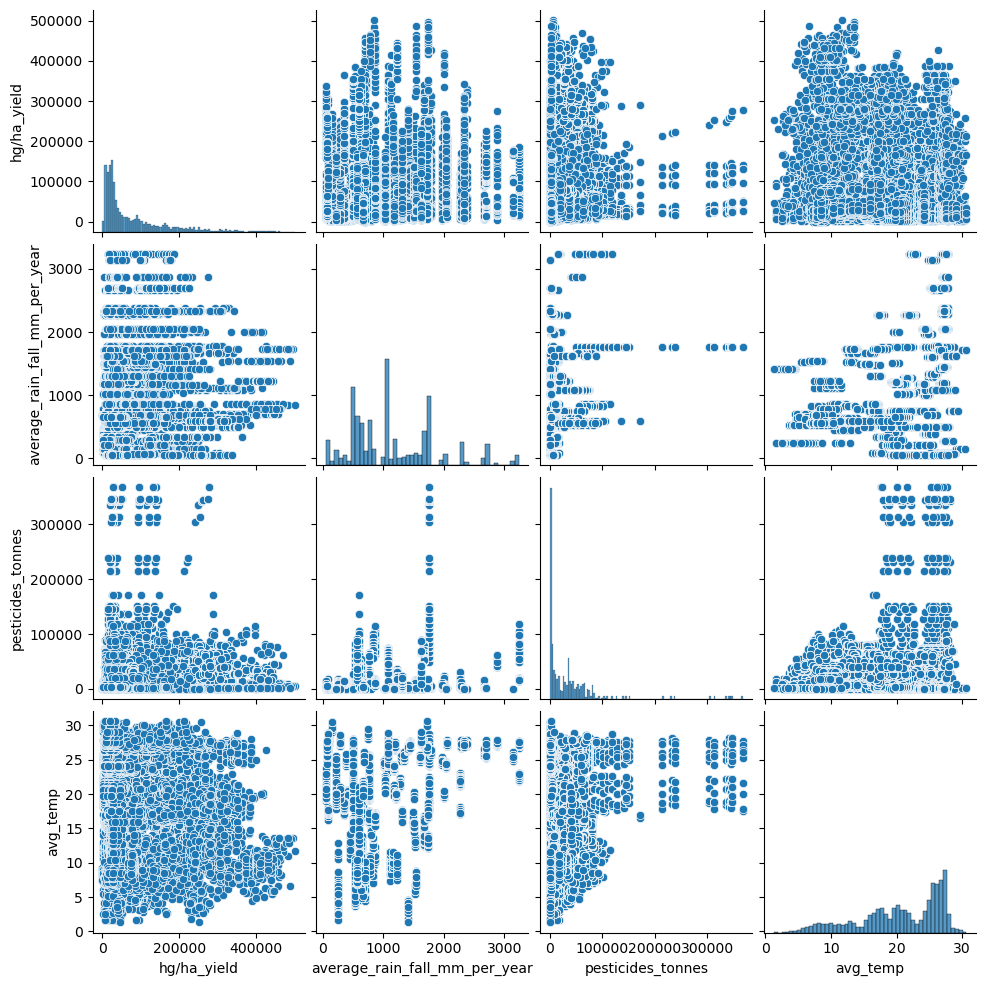

In [ ]:
# Pairplot for numerical variables
sns.pairplot(df[['hg/ha_yield', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']])
plt.show()

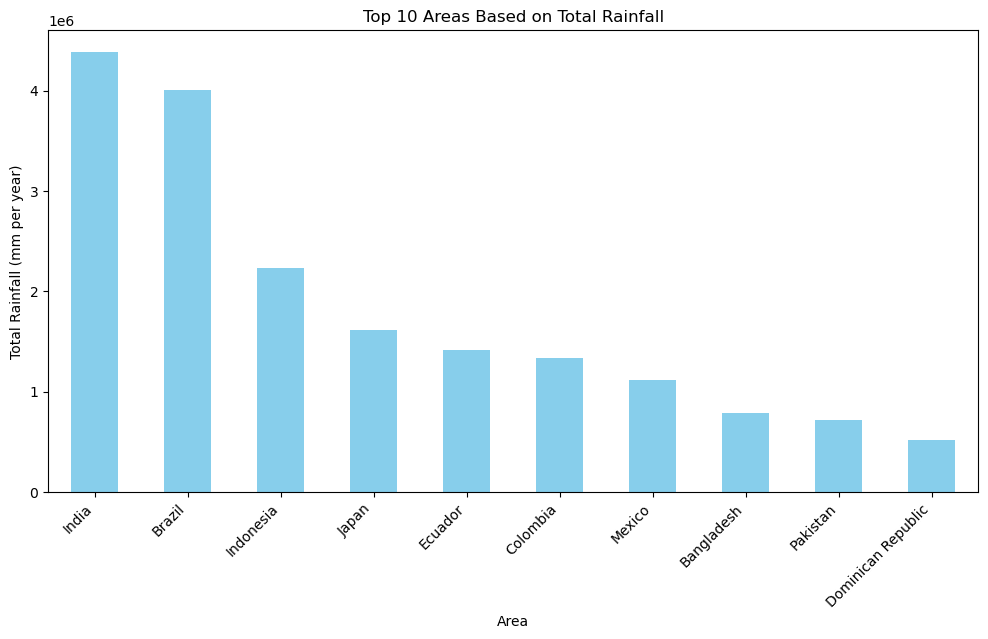

In [ ]:
# Assuming 'Area' is the area column and 'average_rain_fall_mm_per_year' is the rainfall column
area_rainfall_data = df.groupby('Area')['average_rain_fall_mm_per_year'].sum().sort_values(ascending=False)

# Selecting the top 10 areas
top_10_areas = area_rainfall_data.head(10)

# Plotting the bar graph
plt.figure(figsize=(12, 6))
top_10_areas.plot(kind='bar', color='skyblue')
plt.title('Top 10 Areas Based on Total Rainfall')
plt.xlabel('Area')
plt.ylabel('Total Rainfall (mm per year)')
plt.xticks(rotation=45, ha='right')
plt.show()

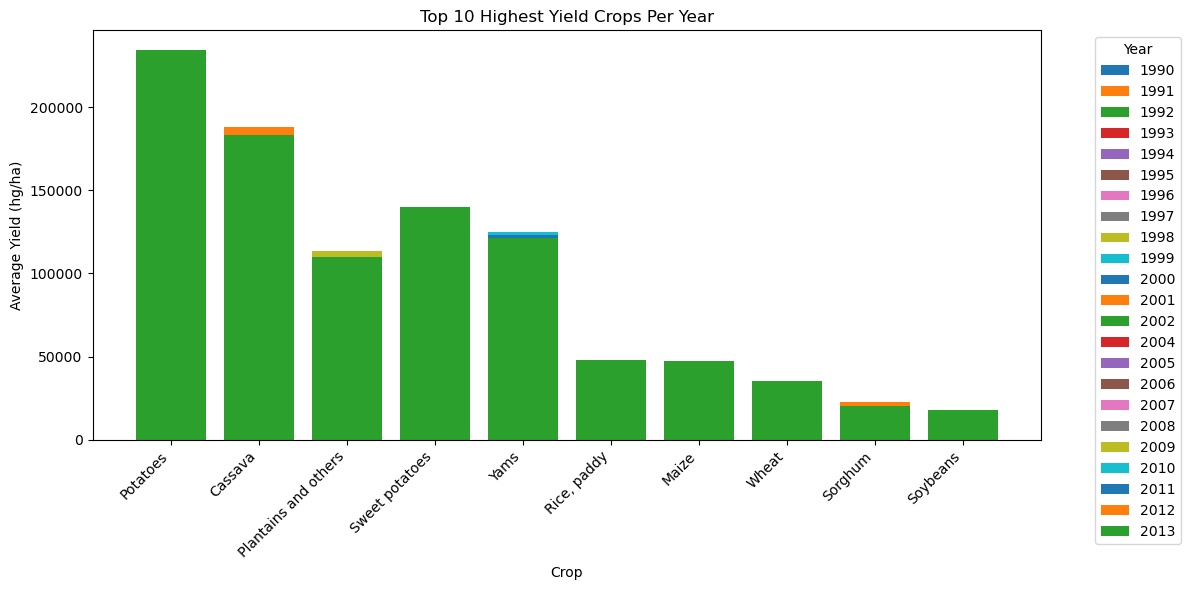

In [ ]:
# Group the data by 'Year' and 'Item', and calculate the mean yield for each crop in each year
yearly_yield_data = df.groupby(['Year', 'Item'])['hg/ha_yield'].mean().reset_index()

# Find the top 10 crops with the highest average yield for each year
top_10_yield_crops = yearly_yield_data.groupby('Year').apply(lambda x: x.nlargest(10, 'hg/ha_yield')).reset_index(drop=True)

# Plotting the bar graph
plt.figure(figsize=(12, 6))
for year, data in top_10_yield_crops.groupby('Year'):
    plt.bar(data['Item'], data['hg/ha_yield'], label=str(year))

plt.title('Top 10 Highest Yield Crops Per Year')
plt.xlabel('Crop')
plt.ylabel('Average Yield (hg/ha)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Year', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

D:\Users\TMP00574\AppData\Local\Temp\1\ipykernel_1644\2799049645.py:17: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


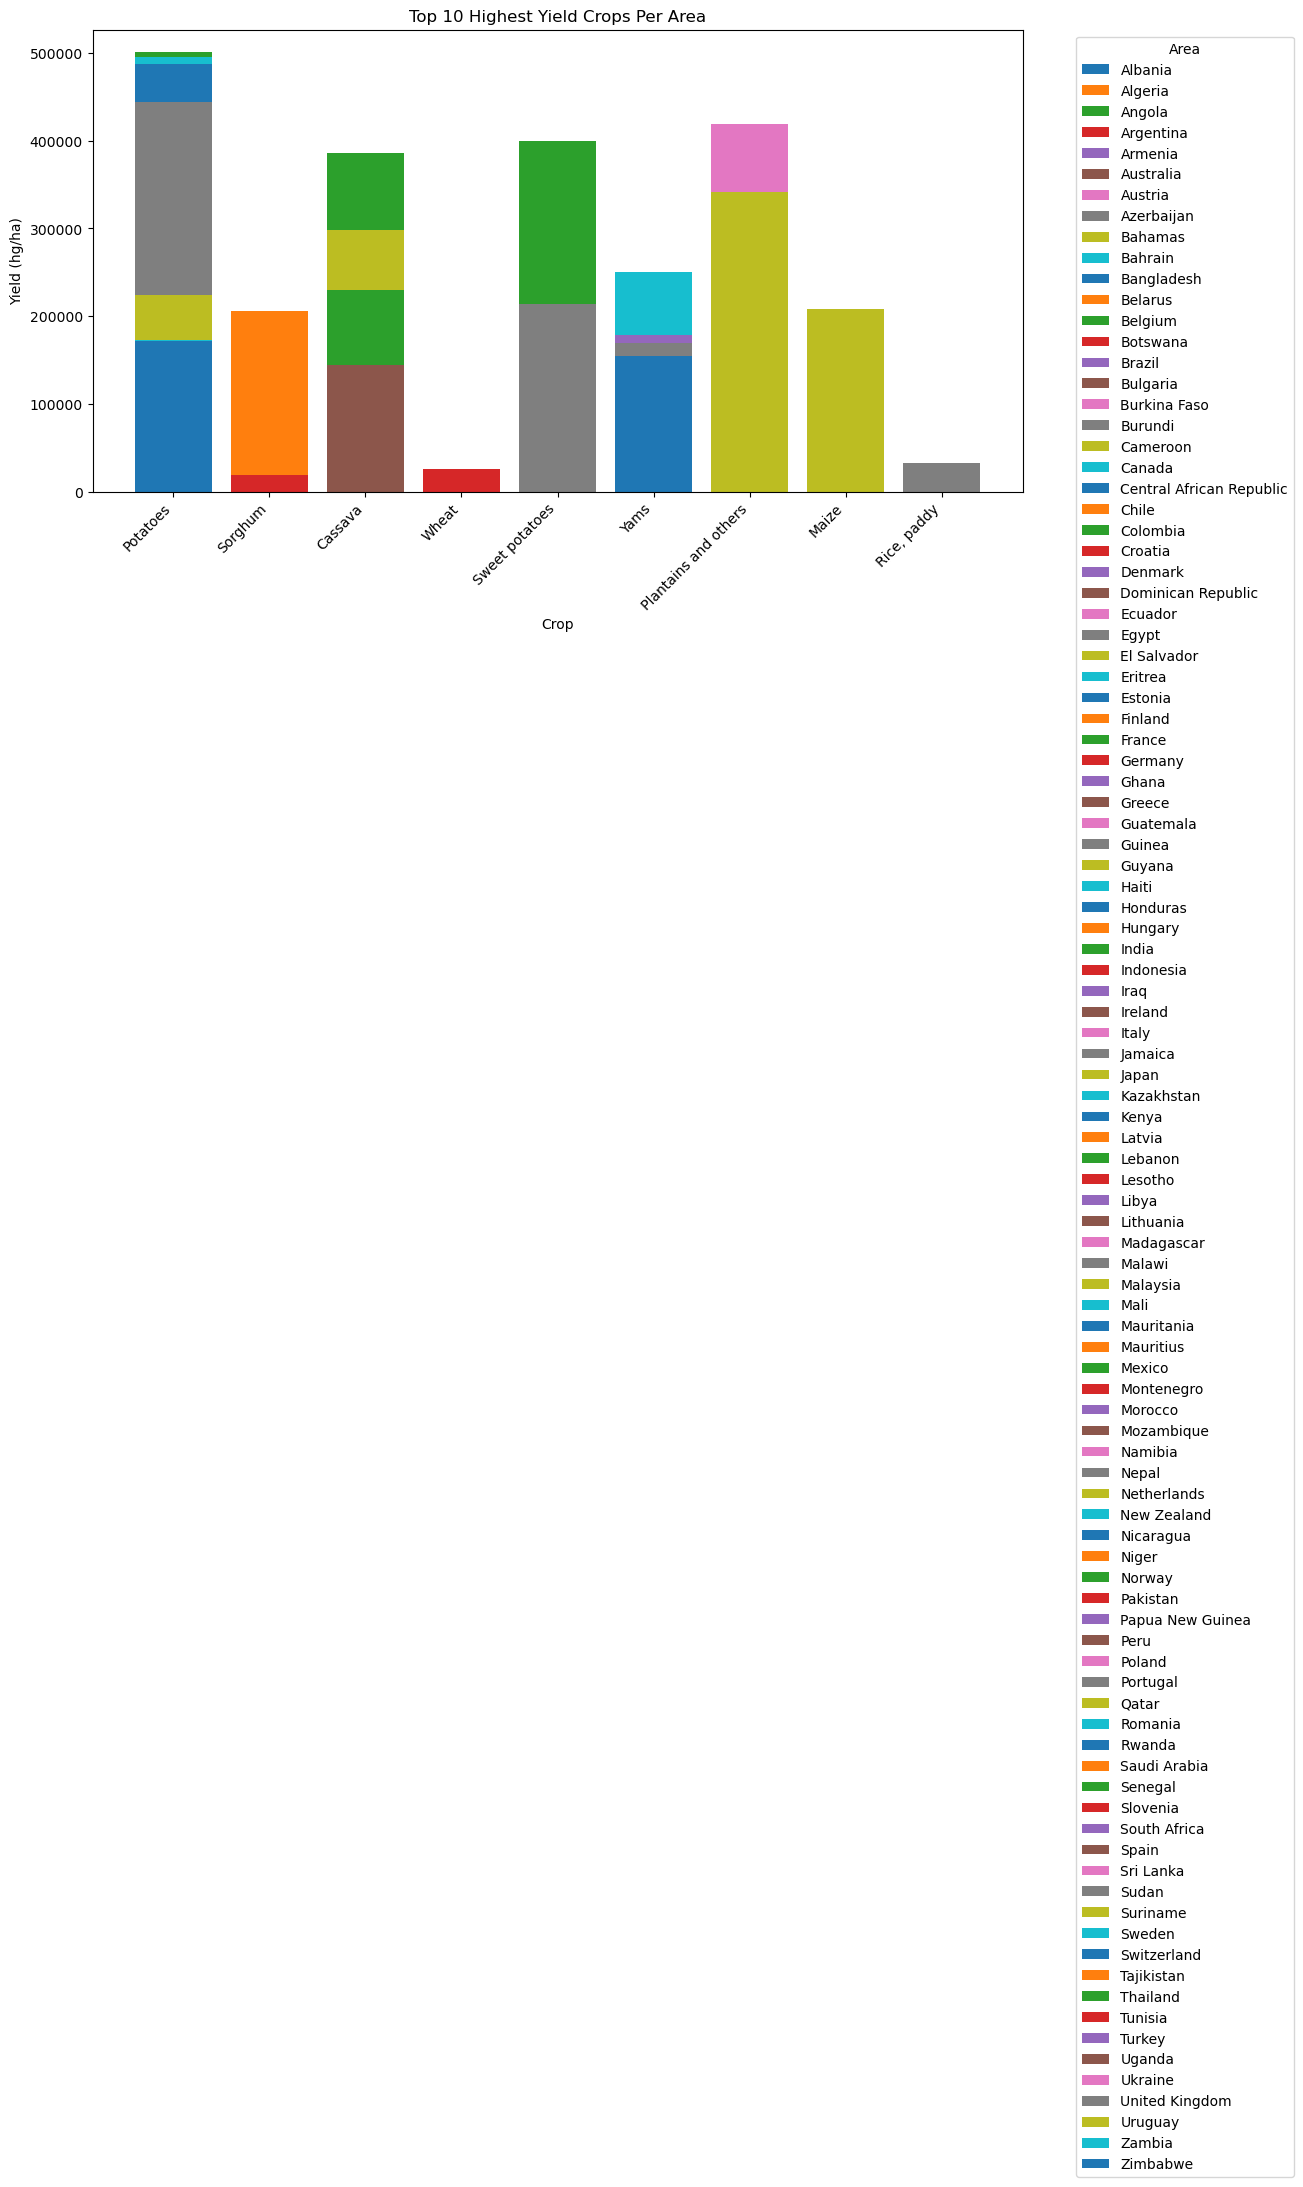

In [ ]:
# Find the top crop for each area
top_yield_crops = df.loc[df.groupby('Area')['hg/ha_yield'].idxmax()]

# Find the top 10 crops with the highest yield for each area
top_10_yield_crops = df.groupby('Area').apply(lambda x: x.nlargest(10, 'hg/ha_yield')).reset_index(drop=True)

# Plotting the bar graph
plt.figure(figsize=(12, 6))
for area, data in top_10_yield_crops.groupby('Area'):
    plt.bar(data['Item'], data['hg/ha_yield'], label=area)

plt.title('Top 10 Highest Yield Crops Per Area')
plt.xlabel('Crop')
plt.ylabel('Yield (hg/ha)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Area', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

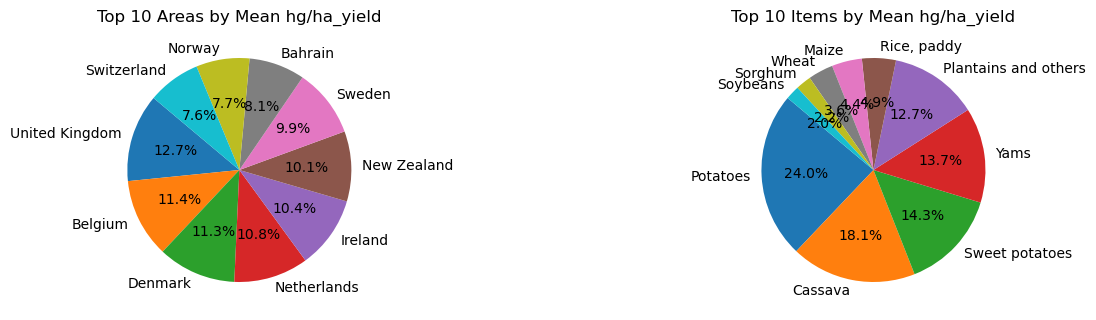

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming df is your DataFrame
# If 'Unnamed: 0' is an index, you can set it as the index using: df.set_index('Unnamed: 0', inplace=True)

# Calculate the mean 'hg/ha_yield' for each 'Area' and 'Item'
mean_yield_by_area = df.groupby('Area')['hg/ha_yield'].mean().nlargest(10)
mean_yield_by_item = df.groupby('Item')['hg/ha_yield'].mean().nlargest(10)

# Plot pie charts for the top 10 'Area' and 'Item'
plt.figure(figsize=(15, 8))

# Pie chart for top 10 'Area'
plt.subplot(2, 2, 1)
plt.pie(mean_yield_by_area, labels=mean_yield_by_area.index, autopct='%1.1f%%', startangle=140)
plt.title('Top 10 Areas by Mean hg/ha_yield')

# Pie chart for top 10 'Item'
plt.subplot(2, 2, 2)
plt.pie(mean_yield_by_item, labels=mean_yield_by_item.index, autopct='%1.1f%%', startangle=140)
plt.title('Top 10 Items by Mean hg/ha_yield')

plt.show()


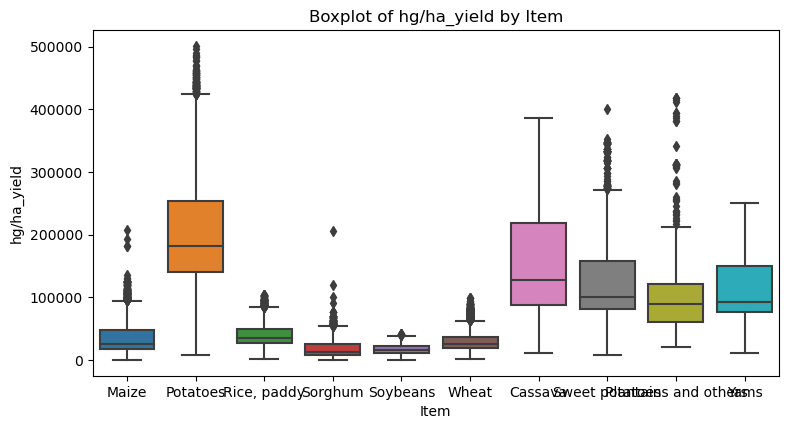

In [ ]:
plt.figure(figsize=(15, 8))
plt.subplot(2, 2, 2)
sns.boxplot(x='Item', y='hg/ha_yield', data=df)
plt.title('Boxplot of hg/ha_yield by Item')
plt.tight_layout()
plt.show()

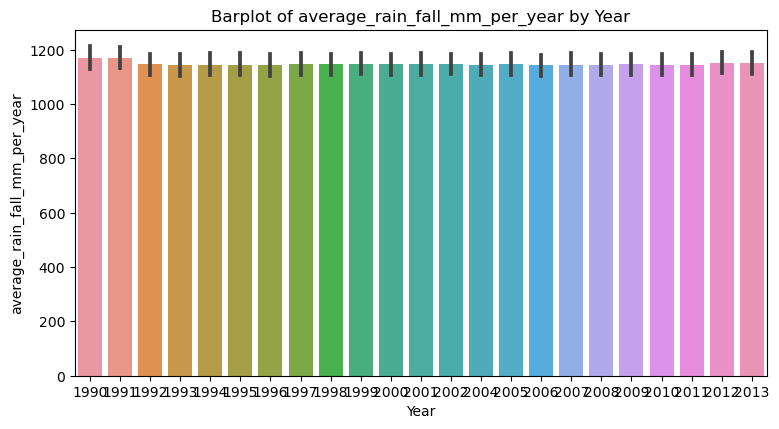

In [ ]:
# Barplot for average rain fall by year
plt.figure(figsize=(15, 8))
plt.subplot(2, 2, 3)
sns.barplot(x='Year', y='average_rain_fall_mm_per_year', data=df)
plt.title('Barplot of average_rain_fall_mm_per_year by Year')
plt.tight_layout()
plt.show()

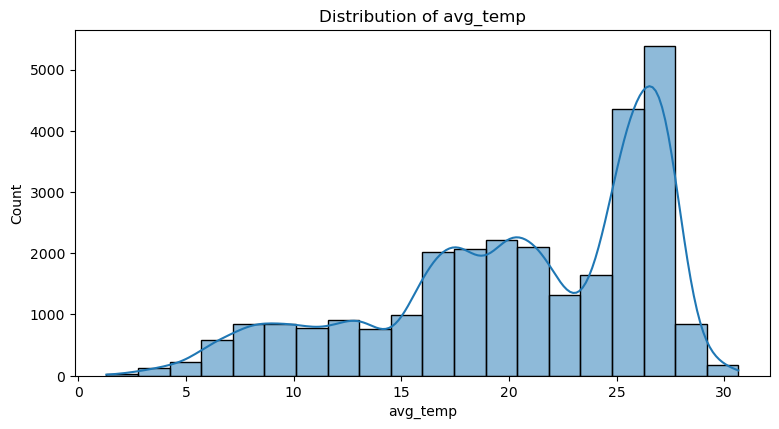

In [ ]:
# Distribution plot for 'avg_temp'
plt.figure(figsize=(15, 8))
plt.subplot(2, 2, 4)
sns.histplot(df['avg_temp'], kde=True, bins=20)
plt.title('Distribution of avg_temp')
plt.tight_layout()
plt.show()

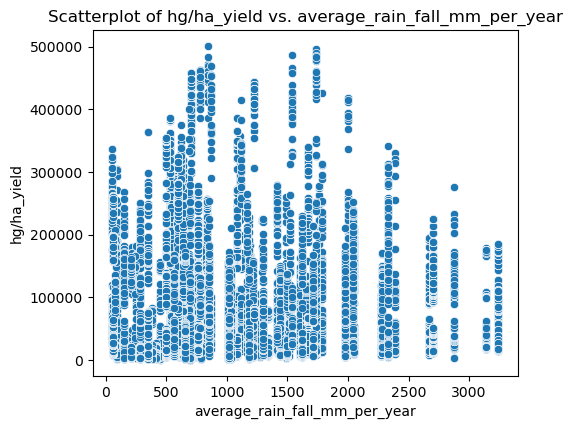

In [ ]:
plt.figure(figsize=(15, 8))
plt.subplot(2, 3, 5)
sns.scatterplot(x='average_rain_fall_mm_per_year', y='hg/ha_yield', data=df)
plt.title('Scatterplot of hg/ha_yield vs. average_rain_fall_mm_per_year')
plt.tight_layout()
plt.show()

D:\Users\TMP00574\AppData\Local\Temp\1\ipykernel_1644\1023432283.py:4: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  corr_matrix = df.corr()


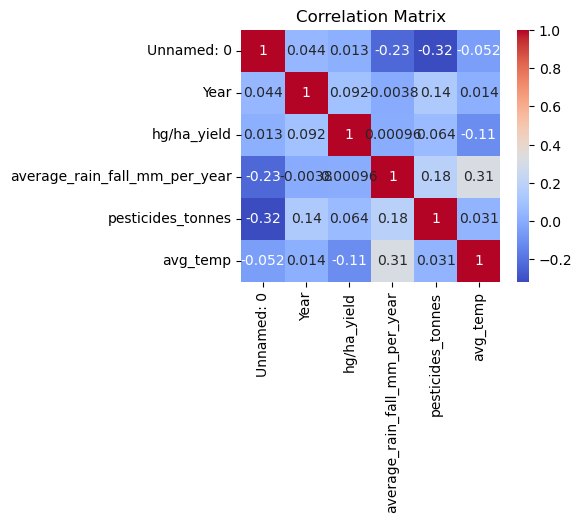

In [ ]:
# Heatmap of correlation matrix
plt.figure(figsize=(15, 8))
plt.subplot(2, 3, 6)
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

In [ ]:
#Encode categorical variables

In [ ]:
le = LabelEncoder()
df['Area'] = le.fit_transform(df['Area'])
df['Item'] = le.fit_transform(df['Item'])

In [ ]:
#Normalize
scaler = StandardScaler()
df[['average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']]

,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,1485.0,121.00,16.37
1,1485.0,121.00,16.37
2,1485.0,121.00,16.37
3,1485.0,121.00,16.37
4,1485.0,121.00,16.37
...,...,...,...
28237,657.0,2550.07,19.76
28238,657.0,2550.07,19.76
28239,657.0,2550.07,19.76
28240,657.0,2550.07,19.76


In [ ]:
#Log transform
df['hg/ha_yield'] = np.log1p(df['hg/ha_yield'])

In [ ]:
#Split training 70% testing 30%
X = df.drop(columns=['hg/ha_yield'])
y = df['hg/ha_yield']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [ ]:
#Algo

In [ ]:
rf_model = RandomForestRegressor(random_state=42)
gbm_model = GradientBoostingRegressor(random_state=42)
svm_model = make_pipeline(StandardScaler(), SVR())
dt_model = DecisionTreeRegressor(random_state=42)

In [ ]:
models = {'Random Forest': rf_model, 'GBM': gbm_model, 'SVM': svm_model, 'Decision Tree':dt_model }
best_model_name = None
best_model = None
best_rmse = float('inf')

In [ ]:
for model_name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    print(f"{model_name} RMSE: {rmse}")

    if rmse < best_rmse:
        best_rmse = rmse
        best_model_name = model_name
        best_model = model

Random Forest RMSE: 0.1549657581607802
GBM RMSE: 0.43989768902334214
SVM RMSE: 0.9473592297511076
Decision Tree RMSE: 0.2113559894442131


In [ ]:
print(f"\nBest Model: {best_model_name} with RMSE: {best_rmse}")


Best Model: Random Forest with RMSE: 0.1549657581607802


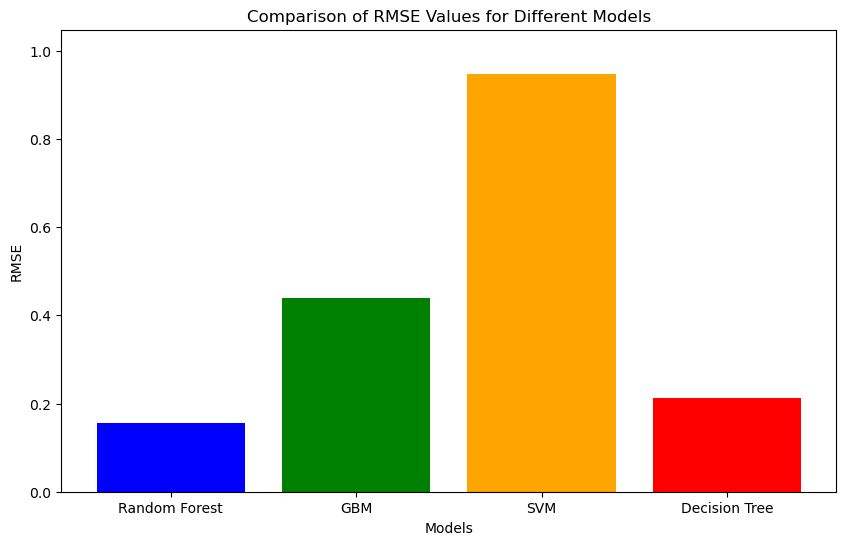

In [ ]:
# RMSE values for different models
models = ['Random Forest', 'GBM', 'SVM', 'Decision Tree']
rmse_values = [0.1549657581607802, 0.43989768902334214, 0.9473592297511076, 0.2113559894442131]

# Plotting the comparison
plt.figure(figsize=(10, 6))
plt.bar(models, rmse_values, color=['blue', 'green', 'orange', 'red'])
plt.title('Comparison of RMSE Values for Different Models')
plt.xlabel('Models')
plt.ylabel('RMSE')
plt.ylim(0, max(rmse_values) + 0.1)  # Adjust the y-axis limit if necessary
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense

# Load your crop yield dataset (replace 'your_dataset.csv' with your actual dataset)
#df = pd.read_csv('your_dataset.csv')

# Assuming 'hg/ha_yield' is the target variable
target_variable = 'hg/ha_yield'

# Select relevant features
features = ['Area', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']

# Extract features and target variable
X = df[features]
y = df[target_variable]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Reshape the data for CNN input
X_train_cnn = X_train_scaled.reshape((X_train_scaled.shape[0], X_train_scaled.shape[1], 1))
X_test_cnn = X_test_scaled.reshape((X_test_scaled.shape[0], X_test_scaled.shape[1], 1))

# Build the CNN model
cnn_model = Sequential([
    Conv1D(filters=64, kernel_size=2, activation='relu', input_shape=(X_train_scaled.shape[1], 1)),
    MaxPooling1D(pool_size=2),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(1)  # Output layer for regression
])

# Compile the CNN model
cnn_model.compile(optimizer='adam', loss='mean_squared_error')

# Train the CNN model
cnn_model.fit(X_train_cnn, y_train, epochs=50, validation_data=(X_test_cnn, y_test))

# Evaluate the CNN model on the test set
cnn_predictions = cnn_model.predict(X_test_cnn)
cnn_rmse = np.sqrt(mean_squared_error(y_test, cnn_predictions))
print(f"CNN RMSE on test set: {cnn_rmse}")


D:\Users\TMP00574\AppData\Local\anaconda3.1\Lib\site-packages\botocore\utils.py:15: DeprecationWarning: 'cgi' is deprecated and slated for removal in Python 3.13
  import cgi
D:\Users\TMP00574\AppData\Local\anaconda3.1\Lib\site-packages\botocore\httpsession.py:41: DeprecationWarning: 'urllib3.contrib.pyopenssl' module is deprecated and will be removed in a future release of urllib3 2.x. Read more in this issue: https://github.com/urllib3/urllib3/issues/2680
  from urllib3.contrib.pyopenssl import orig_util_SSLContext as SSLContext






Epoch 1/50

707/707 [==============================] - 4s 3ms/step - loss: 9.4927 - val_loss: 1.2621
Epoch 2/50
707/707 [==============================] - 2s 3ms/step - loss: 1.2401 - val_loss: 1.2289
Epoch 3/50
707/707 [==============================] - 2s 3ms/step - loss: 1.2261 - val_loss: 1.2966
Epoch 4/50
707/707 [==============================] - 2s 3ms/step - loss: 1.2176 - val_loss: 1.2421
Epoch 5/50
707/707 [==============================] - 2s 3ms/step - loss: 1.2083 - val_loss: 1.2047
Epoch 6/50
707/707 [==============================] - 2s 3ms/step - loss: 1.2095 - val_loss: 1.1969
Epoch 7/50
707/707 [==============================] - 2s 3ms/step - loss: 1.2099 - val_loss: 1.1812
Epoch 8/50
707/707 [==============================] - 2s 3ms/step - loss: 1.2074 - val_loss: 1.2003
Epoch 9/50
707/707 [==============================] - 2s 3ms/step - loss: 1.2006 - val_loss: 1.1992
Epoch 10/50
707/707 [==============================] - 2s 3ms/step - loss: 1.2069 - val_loss: 1

In [ ]:
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, LSTM


In [ ]:
# Extract features and target variable
X = df[features]
y = df[target_variable]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Reshape the data for LSTM input
X_train_lstm = X_train_scaled.reshape((X_train_scaled.shape[0], X_train_scaled.shape[1], 1))
X_test_lstm = X_test_scaled.reshape((X_test_scaled.shape[0], X_test_scaled.shape[1], 1))

# Build the LSTM model
lstm_model = Sequential([
    LSTM(64, activation='relu', input_shape=(X_train_lstm.shape[1], X_train_lstm.shape[2])),
    Dense(1)  # Output layer for regression
])

# Compile the LSTM model
lstm_model.compile(optimizer='adam', loss='mean_squared_error')

# Train the LSTM model
lstm_model.fit(X_train_lstm, y_train, epochs=50, validation_data=(X_test_lstm, y_test))

# Evaluate the LSTM model on the test set
lstm_predictions = lstm_model.predict(X_test_lstm)
lstm_rmse = np.sqrt(mean_squared_error(y_test, lstm_predictions))
print(f"LSTM RMSE on test set: {lstm_rmse}")

Epoch 1/50
707/707 [==============================] - 5s 5ms/step - loss: 11.2761 - val_loss: 1.2274
Epoch 2/50
707/707 [==============================] - 3s 4ms/step - loss: 1.2295 - val_loss: 1.2714
Epoch 3/50
707/707 [==============================] - 3s 4ms/step - loss: 1.2182 - val_loss: 1.2080
Epoch 4/50
707/707 [==============================] - 3s 4ms/step - loss: 1.2117 - val_loss: 1.2045
Epoch 5/50
707/707 [==============================] - 3s 4ms/step - loss: 1.2110 - val_loss: 1.1737
Epoch 6/50
707/707 [==============================] - 3s 4ms/step - loss: 1.2156 - val_loss: 1.2285
Epoch 7/50
707/707 [==============================] - 3s 4ms/step - loss: 1.2182 - val_loss: 1.5498
Epoch 8/50
707/707 [==============================] - 3s 4ms/step - loss: 1.2119 - val_loss: 1.1983
Epoch 9/50
707/707 [==============================] - 3s 4ms/step - loss: 1.2078 - val_loss: 1.5282
Epoch 10/50
707/707 [==============================] - 3s 4ms/step - loss: 1.2129 - val_loss: 1.175

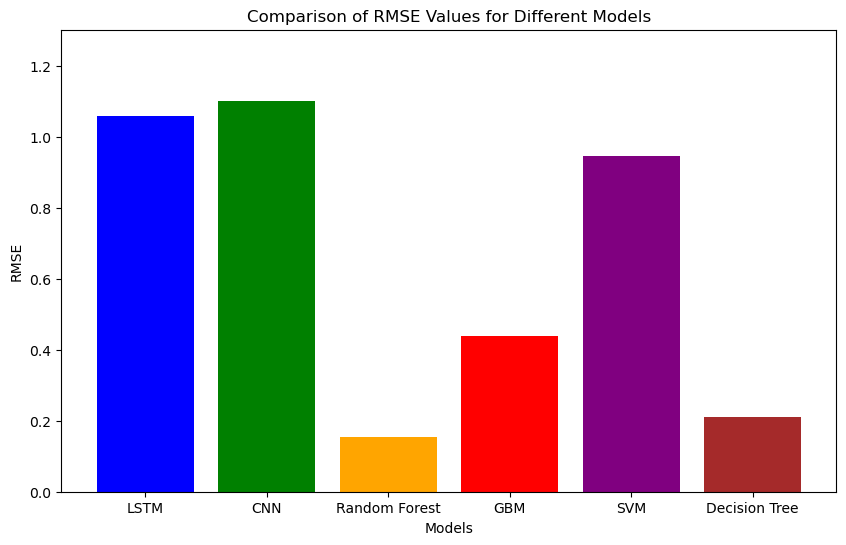

In [ ]:
models = ['LSTM', 'CNN', 'Random Forest', 'GBM', 'SVM', 'Decision Tree']
rmse_values = [1.059811532219632, 1.1031813332812108, 0.1549657581607802, 0.43989768902334214, 0.9473592297511076, 0.2113559894442131]

# Plotting the comparison
plt.figure(figsize=(10, 6))
plt.bar(models, rmse_values, color=['blue', 'green', 'orange', 'red', 'purple', 'brown'])
plt.title('Comparison of RMSE Values for Different Models')
plt.xlabel('Models')
plt.ylabel('RMSE')
plt.ylim(0, max(rmse_values) + 0.2)  # Adjust the y-axis limit if necessary
plt.show()